# 08 — Evaluasi semua model (T35, T35.5, T32, diagnosis)

Hanya membaca `data/processed/predictions.parquet` dari `07_train_models` — **tidak melatih apa pun**.

| Bagian | Isi |
|---|---|
| 1 | Validasi 2019 |
| 2 | **Uji 2020**: metrik (mask valid & all), skill, laju pelanggaran sebelum clipping |
| 3 | Signifikansi: Diebold–Mariano (Holm) + CI bootstrap blok per hari |
| 4 | Ablasi physical consistency (val & uji) + DM |
| 5 | Stratifikasi (jam, musim, kondisi langit) + gambar |
| 6 | Diagnosis: bias bulanan & GFS v15 (FV3), kesulitan tiap tahun |

## 0. Setup

In [8]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, yaml

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import importlib, evaluate as E, models as M, clearsky
for mod in (clearsky, E, M): importlib.reload(mod)

CFG = yaml.safe_load(open(ROOT / "configs" / "config.yaml"))
PROC, RES, FIG = ROOT / "data/processed", ROOT / "results", ROOT / "figures"
KZ = CFG["physics"]["k_max_by_zenith"]; SEED = CFG["seed"]
P = pd.read_parquet(PROC / "predictions.parquet")
BASE = ["pred_clim", "pred_persist", "pred_gfs_raw", "pred_mos"]
ML = [c for c in ("pred_rf", "pred_xgb", "pred_lstm") if c in P]
PRED = BASE + ML
V, T = P[P["split"] == "val"], P[P["split"] == "test"]
NAME = lambda c: c.replace("pred_", "")  # noqa: E731

def holm(p):
    p = np.asarray(p, float); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for i, k in enumerate(order):
        run = max(run, min(1.0, (m - i) * p[k])); adj[k] = run
    return adj
star = lambda p: "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "tidak signifikan"  # noqa: E731
print("Model ML:", [NAME(c) for c in ML])

Model ML: ['rf', 'xgb', 'lstm']


## 1. Validasi 2019

In [9]:
tab_val = E.add_skill(E.evaluate(V, PRED))
tab_val.round(3).to_csv(RES / "val_main.csv")
display(tab_val.loc["valid"].round(3))

,n,RMSE,nRMSE_%,MAE,MBE,R2,skill_vs_clim,skill_vs_persist,skill_vs_gfs_raw
model,,,,,,,,,
pred_clim,3285,150.260,31.269,113.654,-38.633,0.654,0.000,0.126,0.205
pred_persist,3285,171.872,35.767,116.713,-0.578,0.547,-0.144,0.000,0.090
pred_gfs_raw,3285,188.922,39.315,128.202,65.069,0.453,-0.257,-0.099,0.000
pred_mos,3285,148.461,30.895,116.220,-34.087,0.662,0.012,0.136,0.214
pred_rf,3285,124.391,25.886,90.127,-3.011,0.763,0.172,0.276,0.342
pred_xgb,3285,124.312,25.870,89.419,1.303,0.763,0.173,0.277,0.342
pred_lstm,3285,124.316,25.870,88.146,5.557,0.763,0.173,0.277,0.342


## 2. Uji 2020

In [10]:
tab_test = E.add_skill(E.evaluate(T, PRED))
tab_test.round(3).to_csv(RES / "test_main.csv")
display(tab_test.loc["valid"].round(3))
print("Sensitivitas (mask all):"); display(tab_test.loc["all"][["n", "RMSE", "MBE", "skill_vs_clim"]].round(3))

viol = {}
for c in ML:
    k = NAME(c); raw = T[f"raw_{k}"]; cs = T["ghi_cs"].fillna(0); kz = M.kmax_array(T, KZ); dm_ = T["is_day"].to_numpy()
    viol[k] = {"siang_%": E.violation_rate(raw.to_numpy()[dm_], cs.to_numpy()[dm_], kz[dm_])["pct_total"],
               "semua_jam_%": E.violation_rate(raw, cs, kz)["pct_total"]}
viol = pd.DataFrame(viol).T.round(3)
print("Laju pelanggaran prediksi mentah (sebelum clipping):"); display(viol)
viol.to_csv(RES / "test_violation.csv")

,n,RMSE,nRMSE_%,MAE,MBE,R2,skill_vs_clim,skill_vs_persist,skill_vs_gfs_raw
model,,,,,,,,,
pred_clim,3413,153.576,33.434,117.522,-4.458,0.615,0.000,0.274,0.293
pred_persist,3413,211.419,46.026,151.863,-2.675,0.270,-0.377,0.000,0.027
pred_gfs_raw,3413,217.255,47.297,155.631,106.781,0.230,-0.415,-0.028,0.000
pred_mos,3413,154.930,33.728,119.639,3.184,0.608,-0.009,0.267,0.287
pred_rf,3413,143.592,31.260,108.369,-4.434,0.663,0.065,0.321,0.339
pred_xgb,3413,144.603,31.480,107.847,1.615,0.659,0.058,0.316,0.334
pred_lstm,3413,147.347,32.078,108.743,11.692,0.646,0.041,0.303,0.322


Sensitivitas (mask all):


,n,RMSE,MBE,skill_vs_clim
model,,,,
pred_clim,4169,145.839,2.733,0.000
pred_persist,4169,199.590,0.029,-0.369
pred_gfs_raw,4169,206.029,100.319,-0.413
pred_mos,4169,145.029,4.228,0.006
pred_rf,4169,135.325,-2.706,0.072
pred_xgb,4169,136.242,2.838,0.066
pred_lstm,4169,138.121,11.938,0.053


Laju pelanggaran prediksi mentah (sebelum clipping):


,siang_%,semua_jam_%
rf,0.00,0.000
xgb,0.00,0.000
lstm,0.24,0.114


## 3. Signifikansi

In [11]:
rows = []
for mname, mask in E.masks(T).items():
    Ls = E.daily_sq_error(T, PRED, mask)
    pairs = [(a, b) for a in ML for b in BASE] + [(a, b) for i, a in enumerate(ML) for b in ML[i + 1:]]
    for a, b in pairs:
        rows.append({"mask": mname, "model": NAME(a), "vs": NAME(b), **E.diebold_mariano(Ls[a], Ls[b])})
dm = pd.DataFrame(rows)
dm["p_holm"] = dm.groupby("mask")["p"].transform(lambda s: holm(s.to_numpy()))
dm["signifikansi"] = dm["p_holm"].map(star)
dm = dm.round({"mean_diff": 1, "DM": 3, "p": 4, "p_holm": 4})
display(dm[dm["mask"] == "valid"])
dm.to_csv(RES / "test_dm.csv", index=False)

CI = {m: E.block_bootstrap(T, PRED, mask, refs=("pred_clim", "pred_gfs_raw", "pred_persist"), n_boot=2000, seed=SEED)
      for m, mask in E.masks(T).items()}
ci = pd.concat(CI, names=["mask", "besaran"]).round(3)
ci.to_csv(RES / "test_bootstrap_ci.csv")
s = ci.loc["valid"]
display(s[s.index.str.startswith("RMSE")])
display(s[s.index.str.contains("|".join(ML)) & s.index.str.startswith("skill")])

,mask,model,vs,n_hari,mean_diff,DM,p,p_holm,signifikansi
0,valid,rf,clim,366,-2867.3,-5.321,0.0000,0.0000,***
1,valid,rf,persist,366,-23882.6,-12.950,0.0000,0.0000,***
2,valid,rf,gfs_raw,366,-26818.5,-10.410,0.0000,0.0000,***
3,valid,rf,mos,366,-3160.0,-4.825,0.0000,0.0000,***
4,valid,xgb,clim,366,-2577.7,-4.729,0.0000,0.0000,***
5,valid,xgb,persist,366,-23592.9,-13.111,0.0000,0.0000,***
6,valid,xgb,gfs_raw,366,-26528.9,-10.481,0.0000,0.0000,***
7,valid,xgb,mos,366,-2870.3,-4.375,0.0000,0.0001,***
8,valid,lstm,clim,366,-1811.1,-2.544,0.0110,0.0438,*
9,valid,lstm,persist,366,-22826.4,-12.171,0.0000,0.0000,***


,ci_low,median,ci_high
besaran,,,
RMSE_pred_clim,147.127,153.602,160.045
RMSE_pred_persist,201.894,211.211,221.119
RMSE_pred_gfs_raw,206.701,217.243,227.575
RMSE_pred_mos,148.509,154.869,161.534
RMSE_pred_rf,137.313,143.553,149.947
RMSE_pred_xgb,138.114,144.519,151.473
RMSE_pred_lstm,140.122,147.252,154.865


,ci_low,median,ci_high
besaran,,,
skill_pred_rf_vs_pred_clim,0.041,0.065,0.089
skill_pred_xgb_vs_pred_clim,0.033,0.058,0.084
skill_pred_lstm_vs_pred_clim,0.010,0.041,0.069
skill_pred_rf_vs_pred_gfs_raw,0.315,0.339,0.362
skill_pred_xgb_vs_pred_gfs_raw,0.311,0.334,0.357
skill_pred_lstm_vs_pred_gfs_raw,0.297,0.322,0.346
skill_pred_rf_vs_pred_persist,0.294,0.321,0.344
skill_pred_xgb_vs_pred_persist,0.288,0.316,0.340
skill_pred_lstm_vs_pred_persist,0.270,0.303,0.332


## 4. Ablasi physical consistency (XGB)

In [12]:
abl = [c for c in P if c.startswith("abl__")]
def ablation_table(sub):
    t = E.evaluate(sub, abl).reset_index()
    parts = t["model"].str.split("__", expand=True)
    t["target"], t["fitur_fisika"], t["clipping"] = parts[1], parts[2], parts[3]
    k = M.kmax_array(sub, KZ); dmask = sub["is_day"].to_numpy(); cs = sub["ghi_cs"].fillna(0)
    va, vd = {}, {}
    for c in [c for c in P if c.startswith("raw__")]:
        key = c.replace("raw__", "")
        va[key] = E.violation_rate(sub[c], cs, k)["pct_total"]
        vd[key] = E.violation_rate(sub[c].to_numpy()[dmask], cs.to_numpy()[dmask], k[dmask])["pct_total"]
    key = t["target"] + "__" + t["fitur_fisika"]
    t["pelanggaran_siang_%"], t["pelanggaran_semua_jam_%"] = key.map(vd), key.map(va)
    return t.set_index(["mask", "target", "fitur_fisika", "clipping"])[["n", "RMSE", "nRMSE_%", "MBE", "pelanggaran_siang_%", "pelanggaran_semua_jam_%"]]
for name, sub in (("val", V), ("test", T)):
    tb = ablation_table(sub); tb.round(3).to_csv(RES / f"{name}_ablation.csv")
    print(f"Ablasi {name} (mask valid):"); display(tb.xs("valid").round(3))

MAIN = "abl__kc__fis__clip"
rows = []
for mname, mask in E.masks(T).items():
    Ls = E.daily_sq_error(T, abl, mask)
    for b in abl:
        if b != MAIN:
            _, tg, fi, cl = b.split("__")
            rows.append({"mask": mname, "vs_target": tg, "vs_fitur_fisika": fi, "vs_clipping": cl, **E.diebold_mariano(Ls[MAIN], Ls[b])})
da = pd.DataFrame(rows); da["p_holm"] = da.groupby("mask")["p"].transform(lambda s: holm(s.to_numpy()))
da["signifikansi"] = da["p_holm"].map(star)
display(da[da["mask"] == "valid"].round(4)); da.round(4).to_csv(RES / "test_dm_ablation.csv", index=False)

Ablasi val (mask valid):


n     RMSE  nRMSE_%    MBE  \
target fitur_fisika clipping                                  
ghi    nofis        noclip    3289  124.833   26.006  1.306   
                    clip      3289  124.829   26.006  1.290   
       fis          noclip    3289  124.704   25.979  0.175   
                    clip      3289  124.703   25.979  0.171   
kc     nofis        noclip    3289  124.033   25.840 -0.395   
                    clip      3289  124.033   25.840 -0.395   
       fis          noclip    3289  124.237   25.882  1.293   
                    clip      3289  124.237   25.882  1.293   

                              pelanggaran_siang_%  pelanggaran_semua_jam_%  
target fitur_fisika clipping                                                
ghi    nofis        noclip                  0.360                   51.952  
                    clip                    0.360                   51.952  
       fis          noclip                  0.192                   51.906  
                    clip                    0.192                   51.906  
kc     nofis        noclip                  0.000                    0.000  
                    clip                    0.000                    0.000  
       fis          noclip                  0.000                    0.000  
                    clip                    0.000                    0.000

Ablasi test (mask valid):


n     RMSE  nRMSE_%    MBE  \
target fitur_fisika clipping                                  
ghi    nofis        noclip    3415  145.830   31.764  6.416   
                    clip      3415  145.824   31.763  6.392   
       fis          noclip    3415  144.435   31.460  1.158   
                    clip      3415  144.435   31.460  1.156   
kc     nofis        noclip    3415  144.315   31.434 -5.144   
                    clip      3415  144.315   31.434 -5.144   
       fis          noclip    3415  144.561   31.488  1.606   
                    clip      3415  144.561   31.488  1.606   

                              pelanggaran_siang_%  pelanggaran_semua_jam_%  
target fitur_fisika clipping                                                
ghi    nofis        noclip                  0.240                   51.582  
                    clip                    0.240                   51.582  
       fis          noclip                  0.072                   51.526  
                    clip                    0.072                   51.526  
kc     nofis        noclip                  0.000                    0.000  
                    clip                    0.000                    0.000  
       fis          noclip                  0.000                    0.000  
                    clip                    0.000                    0.000

,mask,vs_target,vs_fitur_fisika,vs_clipping,n_hari,mean_diff,DM,p,p_holm,signifikansi
0,valid,ghi,nofis,noclip,366,-294.2145,-1.1883,0.2347,1.0,tidak signifikan
1,valid,ghi,nofis,clip,366,-292.5454,-1.1814,0.2375,1.0,tidak signifikan
2,valid,ghi,fis,noclip,366,73.5315,0.4320,0.6657,1.0,tidak signifikan
3,valid,ghi,fis,clip,366,73.5587,0.4322,0.6656,1.0,tidak signifikan
4,valid,kc,nofis,noclip,366,68.6906,0.3690,0.7121,1.0,tidak signifikan
5,valid,kc,nofis,clip,366,68.6906,0.3690,0.7121,1.0,tidak signifikan
6,valid,kc,fis,noclip,366,0.0000,0.0000,1.0000,1.0,tidak signifikan


## 5. Stratifikasi + gambar

RMSE per jam:


,pred_clim,pred_persist,pred_gfs_raw,pred_mos,pred_rf,pred_xgb,pred_lstm,n
target_hour_wib,,,,,,,,
7,9.6,36.4,24.0,23.4,23.9,23.7,24.3,108
8,75.6,105.0,96.4,76.8,72.3,72.7,73.3,349
9,117.1,153.4,159.2,117.3,109.7,109.6,110.7,340
10,156.9,222.2,227.0,161.9,148.6,148.9,147.7,290
11,175.5,236.9,219.9,173.3,161.2,160.4,162.7,320
12,190.2,252.3,275.5,189.3,177.0,178.1,182.9,326
13,192.5,268.1,312.9,195.5,181.8,186.6,192.8,338
14,191.5,269.5,258.6,187.6,177.4,180.4,187.2,353
15,175.9,245.2,240.0,176.5,164.6,164.7,167.1,361


RMSE per musim:


,pred_clim,pred_persist,pred_gfs_raw,pred_mos,pred_rf,pred_xgb,pred_lstm,n
target_day,,,,,,,,
DJF,172.3,247.5,251.4,172.9,164.7,168.1,170.9,875
JJA,121.2,147.1,140.3,120.0,101.8,101.3,105.5,893
MAM,151.9,208.8,227.3,154.6,147.6,146.5,154.1,850
SON,165.6,231.5,236.0,168.6,154.0,155.5,152.2,795


RMSE per kc_bin:


,pred_clim,pred_persist,pred_gfs_raw,pred_mos,pred_rf,pred_xgb,pred_lstm,n
y_kc,,,,,,,,
"berawan (<0,4)",246.3,302.0,367.3,264.0,236.0,241.6,252.0,559
"sebagian (0,4–0,8)",109.1,194.2,225.8,106.0,108.1,112.7,120.6,1430
"cerah (>0,8)",144.1,182.9,94.6,137.5,125.8,120.2,111.8,1424


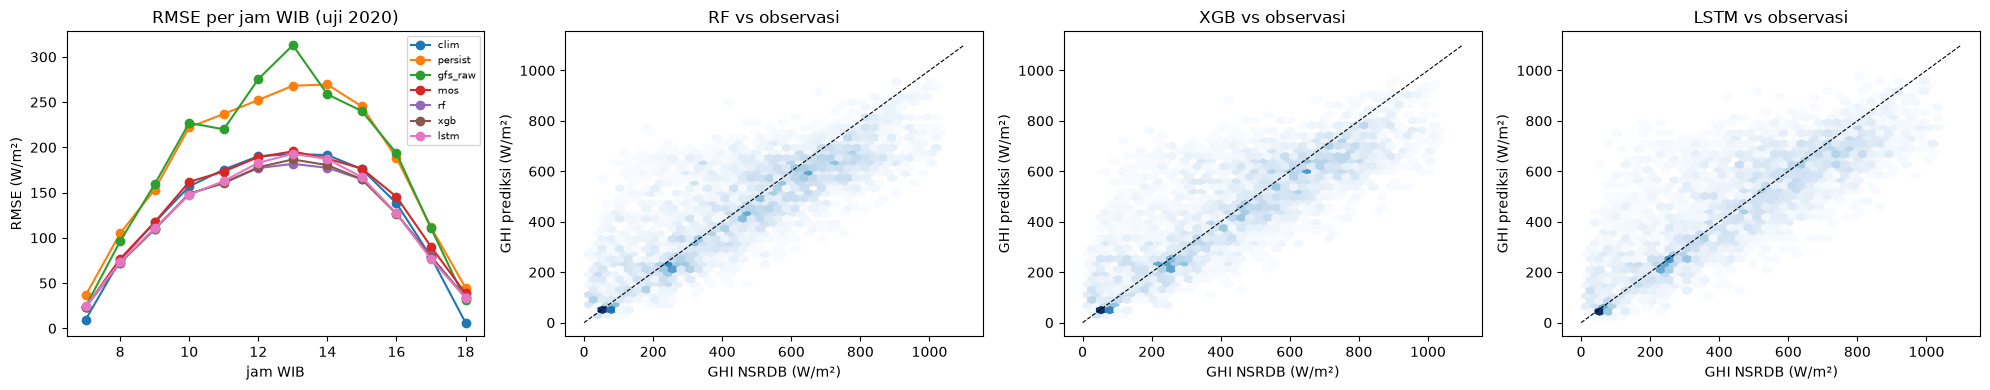

In [13]:
STRAT = {}
for by in ("jam", "musim", "kc_bin"):
    STRAT[by] = E.stratify(T, PRED, by); STRAT[by].round(2).to_csv(RES / f"test_strat_{by}.csv")
    print(f"RMSE per {by}:"); display(STRAT[by].round(1))

fig, ax = plt.subplots(1, 1 + len(ML), figsize=(5 * (1 + len(ML)), 4))
for c in PRED:
    ax[0].plot(STRAT["jam"].index, STRAT["jam"][c], marker="o", label=NAME(c))
ax[0].set(title="RMSE per jam WIB (uji 2020)", xlabel="jam WIB", ylabel="RMSE (W/m²)"); ax[0].legend(fontsize=7)
m = E.masks(T)["valid"]
for a, c in zip(ax[1:], ML):
    a.hexbin(T.loc[m, "y_ghi"], T.loc[m, c], gridsize=40, mincnt=1, cmap="Blues"); a.plot([0, 1100], [0, 1100], "k--", lw=.8)
    a.set(title=f"{NAME(c).upper()} vs observasi", xlabel="GHI NSRDB (W/m²)", ylabel="GHI prediksi (W/m²)")
plt.tight_layout(); plt.savefig(FIG / "test_rmse_by_hour_scatter.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Diagnosis: bias bulanan (GFS v15/FV3) & kesulitan tiap tahun

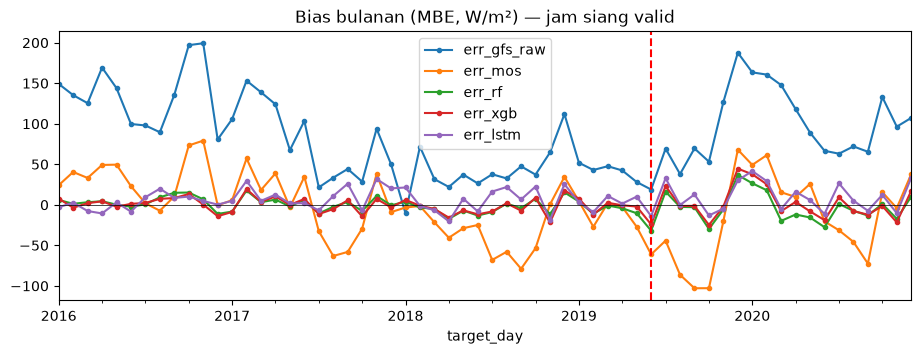

gfs_raw_MBE  gfs_raw_RMSE  mos_MBE  mos_RMSE  rf_MBE  rf_RMSE  \
    split                                                                  
v14 train         84.8         209.4     -0.2     150.5     0.6     92.2   
    val           36.2         200.2    -14.7     145.9    -8.1    137.7   
v15 test         106.7         217.2      3.2     154.9    -4.4    143.6   
    val           87.0         179.6    -48.9     150.2     0.9    113.0   

           xgb_MBE  xgb_RMSE  lstm_MBE  lstm_RMSE  
    split                                          
v14 train     -0.2     111.0       6.6      128.2  
    val       -4.3     136.1       0.1      134.1  
v15 test       1.6     144.6      11.7      147.3  
    val        5.6     114.3       9.7      116.2

,kc_harian_rata2,kc_harian_std,perubahan_harian_|Δkc|,"%_hari_berawan_(kc<0,5)",RMSE_persistence
target_day,,,,,
2016,0.664,0.160,0.137,16.667,196.925
2017,0.696,0.182,0.135,15.068,187.186
2018,0.734,0.191,0.126,10.440,185.190
2019,0.767,0.184,0.120,9.315,171.872
2020,0.704,0.183,0.148,13.661,211.419



Ringkas untuk decisions.md:
- 2026-11-27 | Evaluasi uji 2020 (valid, n=3413): RMSE clim 153.6 / persist 211.4 / gfs_raw 217.3 / mos 154.9 / rf 143.6 / xgb 144.6 / lstm 147.3 W/m². | results/test_*.csv | Bab IV


In [14]:
FV3_DAY = pd.Timestamp("2019-06-14")
e = P[E.masks(P)["valid"]].copy()
cols = ["pred_gfs_raw", "pred_mos"] + ML
for c in cols:
    e[f"err_{NAME(c)}"] = e[c] - e["y_ghi"]
ecols = [f"err_{NAME(c)}" for c in cols]
mon = e.groupby(e["target_day"].dt.to_period("M"))[ecols].mean()
ax = mon.plot(figsize=(11, 3.5), marker=".", title="Bias bulanan (MBE, W/m²) — jam siang valid")
ax.axvline(pd.Period("2019-06", "M"), c="r", ls="--"); ax.axhline(0, c="k", lw=.5)
plt.savefig(FIG / "bias_monthly_fv3.png", dpi=150, bbox_inches="tight"); plt.show()
per = np.where(e["target_day"] < FV3_DAY, "v14", "v15")
fv3 = e.groupby([per, e["split"]])[ecols].agg(["mean", lambda s: np.sqrt((s ** 2).mean())])
fv3.columns = [f"{a.replace('err_', '')}_{'MBE' if b == 'mean' else 'RMSE'}" for a, b in fv3.columns]
display(fv3.round(1)); fv3.round(2).to_csv(RES / "diag_fv3_bias.csv")

daily = e.groupby("target_day")["y_kc"].mean(); yr = daily.index.year
stat = pd.DataFrame({"kc_harian_rata2": daily.groupby(yr).mean(), "kc_harian_std": daily.groupby(yr).std(),
                     "perubahan_harian_|Δkc|": daily.diff().abs().groupby(yr).mean(),
                     "%_hari_berawan_(kc<0,5)": (daily < 0.5).groupby(yr).mean() * 100,
                     "RMSE_persistence": e.groupby(e["target_day"].dt.year).apply(
                         lambda g: np.sqrt(((g["pred_persist"] - g["y_ghi"]) ** 2).mean()), include_groups=False)}).round(3)
display(stat); stat.to_csv(RES / "diag_year_difficulty.csv")

v = tab_test.loc["valid"]
lines = " / ".join(f"{NAME(c)} {v.loc[c, 'RMSE']:.1f}" for c in PRED)
print(f"\nRingkas untuk decisions.md:\n- {pd.Timestamp.today():%Y-%m-%d} | Evaluasi uji 2020 (valid, n={int(v.iloc[0]['n'])}): RMSE {lines} W/m². | results/test_*.csv | Bab IV")